[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AIforPhilanthropy/eduall/blob/main/protocols/agentic_mimicking_protocols/TraditionalML/4_Hybrid/Hybrid_Protocol.ipynb)

# EduAll Foundation — Grant Call 2026
## Group Project Report: Traditional Machine Learning — Two-Stage Hybrid: Segmentation, then Supervised Re-ranking

**Protocol:** `protocols/humaAI_Machine_Learning.pdf` — Human-AI condition, Approach 1 of 3 (traditional ML).
**Modeling path chosen:** example 4 of the protocol, *Unsupervised segmentation by need/merit profile → supervised ranker within each segment*.
**Group:** Group ML-4, four students (A, B, C, D).
**Input data:** `data/EduAll_500_Applications_Dataset.csv` and the 500 application files in
`data/individual_applications/`.

We first let k-means find segments of applicants with similar need and merit profiles. Then, inside each segment, we fit a small ridge-regression ranker against a declared points rubric. Each segment receives a budget envelope, and applicants are funded in their segment's order.

This notebook **is** our project report. It follows the protocol's four steps:

1. **Anchor the model's objective** — from the mission statement and the grant call: the 7 eligibility
   (hard, pass/fail) and 5 priority (soft, scored) criteria, plus the nuances we add as a group.
2. **Choose and execute a modeling path** — and why we chose it.
3. **Build and validate** — features used and excluded, fitting, the validation criterion, seed-sensitivity
   runs, and a human review of the model's output against the underlying records.
4. **Documentation and reproducibility** — full specification, which decisions are the model's and which
   are ours, the final funding list, and the output files `decision_progression.csv` and
   `final_allocation.csv`.

In [ ]:
# --- Get the data -------------------------------------------------------------------------------
# On Google Colab this cell downloads the course repository (data + notebooks) from GitHub and moves into this
# notebook's folder, so every data path below works as on the course computers. Locally it does nothing.
import os, pathlib, subprocess
REPO_URL = "https://github.com/AIforPhilanthropy/eduall.git"
NOTEBOOK_DIR = "protocols/agentic_mimicking_protocols/TraditionalML/4_Hybrid"          # this notebook's folder inside the repository
here = pathlib.Path.cwd()
if not any((p / "data" / "EduAll_500_Applications_Dataset.csv").exists() for p in [here, *here.parents]):
    if not pathlib.Path("/content/eduall").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "/content/eduall"], check=True)
    os.chdir(pathlib.Path("/content/eduall") / NOTEBOOK_DIR)
print("working directory:", os.getcwd())

---
## Step 1 — Anchor the model's objective

*Budget: ~13.0h for a 4-student group.*

We read the foundation's **Organization Profile** (mission and values) and the **Grant Call 2026**
(eligibility, ineligible categories, priority considerations, weighted evaluation criteria, award rules),
and the FAQ where the call refers to it.

**Mission (Organization Profile):** *"Our focus is not on academic excellence or competition, but rather on
identifying students with genuine financial need and providing them with the means to pursue their
studies."*

### 1.1 Eligibility criteria (hard, pass/fail, n = 7)

These are the call's seven *Primary Eligibility Requirements*. The last column says how we check each one in
the data, including our group's decisions where the call leaves room for interpretation.

| # | Criterion (Grant Call) | How we check it | Our decision |
|---|---|---|---|
| H1 | Non-Swiss citizen | `country_origin` | All 500 applicants are international by construction: pass. |
| H2 | Legally residing in Switzerland (valid permit B, C, F, S...; pending permits case by case) | `residency_permit`, plus the ineligible category *"Permit C and significant family financial resources"* | Permits B, C, F, S pass; Pending permits are eligible and *conditional*. Permit C with a supporting household of CHF 6,500/month or more fails ("significant family resources"). |
| H3 | Accepted or enrolled at an accredited Swiss institution | `university` | All listed institutions are accredited: pass. |
| H4 | Documented genuine financial need | expected 2027/28 shortfall `monthly_expenses − family support − expected personal income`, for the months of study inside the grant period (Sep 2027 – Aug 2028) | Pass if the expected 2027/28 shortfall is positive in the grant period (months from the completion date in the file). |
| H5 | Satisfactory academic standing, normally GPA ≥ 2.5 (exceptions if the reasons are explained) | `gpa`, `academic_standing` | GPA ≥ 2.5 passes. Below 2.5: eligible, but the award is *conditional* on the explanation the call requires, checked at interview. |
| H6 | Bachelor's, master's or doctoral degree, full-time or part-time | `study_level`, `study_mode` | All applicants qualify: pass. |
| H7 | No outstanding legal or immigration issues | not observable in the data | Assumed satisfied; pending permits are handled in H2. |


### 1.2 Priority criteria (soft, scored, n = 5)

| # | Criterion (Grant Call weight) | What it means for us | Variables |
|---|---|---|---|
| S1 | Financial need (40%) | Shortfall ratio, and a household below CHF 1,500/month (roughly the poverty line for a family abroad in CHF terms). | `shortfall_ratio`, `family_household_income_chf` |
| S2 | Academic motivation & potential (25%) | Satisfactory standing, and progress within the study level. | `gpa`, `academic_standing`, `progress` (within level) |
| S3 | Personal resilience & determination (20%) | Resilience factors declared. | `resilience_*` |
| S4 | Contribution to diversity (10%) | Low-income country, first generation. | `gni_tier`, `risk_first_generation` |
| S5 | Alignment with EduAll values (5%) | Community and volunteer commitment. | `resilience_community_engagement`, `resilience_volunteer_experience` |

The call also names **priority groups**: students from low-income countries (GNI per capita below USD 3,000,
`gni_tier == 1`), first-generation students, students from under-represented regions, and students
demonstrating exceptional resilience.


### 1.3 Nuances we add as a group

* **Compare like with like.** A single ranking compares a part-time student with a working spouse directly with a
  refugee student without any support. We want the model to find groups of similar applicants first, and to rank
  within those groups. How much money each group gets then becomes an explicit, documented decision.
* **Savings.** Savings above a CHF 2,000 reserve are deducted in full from the grant-period request. The call says
  savings are taken into account, and we read this strictly.
* **Award size.** 65% of the request, minimum CHF 1,000.

❓ **Question for students:** budget envelopes guarantee every segment some funding. Under what circumstances
is that fairer than a single ranking, and when does it become a quota?

---
## Step 2 — Choose and execute a modeling path

*Budget: ~27.6h.*

We chose the protocol's **two-stage hybrid** path:

1. **Unsupervised segmentation.** k-means on standardised need and merit features; k by silhouette; stability
   across seeds.
2. **Supervised re-ranking.** Within each segment, a ridge regression is trained against a declared *points rubric*
   (our pseudo-label), with 5-fold cross-validation. The *out-of-fold* prediction is used as the ranking score, so
   no applicant is ranked by a model that has seen their own label.

In [1]:
import pathlib, re, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
warnings.filterwarnings("ignore")
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import silhouette_score, adjusted_rand_score, r2_score
from scipy.stats import spearmanr
SEED = 2026
mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

In [2]:
# Data: works from the course folder (protocols/agentic_mimicking_protocols/TraditionalML/<approach>/)
# and on Google Colab (upload the CSV and individual_applications.zip when asked).
CANDIDATES = [pathlib.Path("../../../../data"), pathlib.Path("../../../data"), pathlib.Path("data"), pathlib.Path(".")]
DATA = next((b for b in CANDIDATES if (b / "EduAll_500_Applications_Dataset.csv").exists()), None)
if DATA is None:
    from google.colab import files            # only reached on Colab
    print("Upload EduAll_500_Applications_Dataset.csv and individual_applications.zip")
    files.upload()
    DATA = pathlib.Path(".")
APPS = DATA / "individual_applications"
if not APPS.exists() and (DATA / "individual_applications.zip").exists():
    with zipfile.ZipFile(DATA / "individual_applications.zip") as z:
        z.extractall(DATA)

df = pd.read_csv(DATA / "EduAll_500_Applications_Dataset.csv", keep_default_na=False).set_index("student_id", drop=False)
df.index.name = None
docs = {sid: (APPS / f"{sid}_application.md").read_text(encoding="utf-8") for sid in df.student_id}
print(df.shape, "| application files:", len(docs))

(500, 44) | application files: 500


In [3]:
# Quantities every approach needs, computed from the call's own rules
RISK = ["risk_first_generation", "risk_refugee_asylum", "risk_disability", "risk_housing_insecurity",
        "risk_family_emergency", "risk_language_barrier", "risk_parent_student", "risk_undocumented_status"]
RESIL = ["resilience_volunteer_experience", "resilience_work_experience", "resilience_leadership_role",
         "resilience_community_engagement", "resilience_overcame_adversity"]
CAP = {"Bachelor's": 8000, "Master's": 6500, "Doctoral": 5000}          # annual maximum by level
REQUIRED = {"Bachelor's": 40, "Master's": 12, "Doctoral": 12}             # courses per degree

# Expected completion is stated in each application form; we read it from the file.
MONTH = {"January": 1, "July": 7}
def completion(text):
    m = re.search(r"\*\*Expected Completion:\*\*\s*(January|July) (\d{4})", text)
    return (int(m.group(2)), MONTH[m.group(1)]) if m else (None, None)

df["completion_year"], df["completion_month"] = zip(*[completion(docs[s]) for s in df.student_id])
# months of study inside the grant period Sep 2027 - Aug 2028 (finish Jan 2028 -> 5, Jul 2028 -> 11, later -> 12)
grant_end = (2028, 8)
def months_in_grant(y, m):
    if y is None: return 12
    if (y, m) < (2027, 9): return 0
    if (y, m) >= grant_end: return 12
    return (y - 2027) * 12 + m - 9 + 1
df["months_in_grant"] = [months_in_grant(y, m) for y, m in zip(df.completion_year, df.completion_month)]
df["months_to_completion"] = [(y - 2026) * 12 + m - 9 + 1 for y, m in zip(df.completion_year, df.completion_month)]  # from Sep 2026

df["need_2027"] = (df.monthly_expenses_chf - df.family_income_chf - df.expected_personal_income_2027_chf).clip(lower=0)
df["shortfall_ratio"] = (df.need_2027 / df.monthly_expenses_chf).clip(0, 1)
df["risk_count"] = df[RISK].sum(axis=1)
df["resil_count"] = df[RESIL].sum(axis=1)
df["progress"] = (df.courses_completed / df.study_level.map(REQUIRED)).clip(0, 1)
df["cap_period"] = df.study_level.map(CAP) * df.months_in_grant / 12
print(df.months_in_grant.value_counts().sort_index().to_dict())

{5: 50, 11: 283, 12: 167}


In [4]:

PERMIT_C_LIMIT = 6500      # "significant family financial resources" for Permit C (our threshold)
df["H1"] = np.where(df.country_origin != "Switzerland", "pass", "fail")
df["H2"] = np.select([(df.residency_permit == "C") & (df.family_household_income_chf >= PERMIT_C_LIMIT),
                      df.residency_permit == "Pending"],
                     ["fail (Permit C, household >= CHF 6,500)", "conditional (permit pending)"], "pass")
df["H3"] = np.where(df.university.str.len() > 0, "pass", "fail")
df["H4"] = np.where((df.need_2027 > 0) & (df.months_in_grant > 0), "pass", "fail (no shortfall in grant period)")
df["H5"] = np.where(df.gpa >= 2.5, "pass", "conditional")   # explanation required at interview
df["H6"] = np.where(df.study_level.isin(CAP) & df.study_mode.isin(["Full-time", "Part-time"]), "pass", "fail")
df["H7"] = "pass (assumed)"
HARD = ["H1", "H2", "H3", "H4", "H5", "H6", "H7"]
df["eligible"] = ~df[HARD].apply(lambda c: c.str.startswith("fail")).any(axis=1)
df["conditional"] = df[HARD].apply(lambda c: c.str.startswith("conditional")).any(axis=1)
summary = pd.DataFrame({h: df[h].value_counts() for h in HARD}).fillna(0).astype(int)
display(summary)
print(f"eligible: {df.eligible.sum()} of {len(df)} (of which conditional: {(df.eligible & df.conditional).sum()})")

,H1,H2,H3,H4,H5,H6,H7
conditional,0,0,0,0,81,0,0
conditional (permit pending),0,16,0,0,0,0,0
"fail (Permit C, household >= CHF 6,500)",0,20,0,0,0,0,0
fail (no shortfall in grant period),0,0,0,76,0,0,0
pass,500,464,500,424,419,500,0
pass (assumed),0,0,0,0,0,0,500


eligible: 413 of 500 (of which conditional: 74)


In [5]:
# Award request for the grant period: shortfall x months, minus other scholarships and savings, capped
# Savings: savings above a CHF 2,000 reserve are deducted in full
df["scholarship_period"] = df.external_scholarship_amount_chf * df.months_in_grant / 12
df["savings_counted"] = (df.savings_chf - 2000).clip(lower=0)
df["request"] = (df.need_2027 * df.months_in_grant - df.scholarship_period - df.savings_counted).clip(lower=0)
df["request"] = np.minimum(df.request, df.cap_period).round()
print(f"eligible applicants with a positive request: {(df.eligible & (df.request > 0)).sum()}; "
      f"their total request: CHF {df.loc[df.eligible, 'request'].sum():,.0f} vs budget CHF 500,000")

eligible applicants with a positive request: 369; their total request: CHF 1,990,269 vs budget CHF 500,000


---
## Step 3 — Build and validate

*Budget: ~81.2h.*

### 3.1 Stage 1: segmentation features

**Used for segmentation (7, standardised):** `shortfall_ratio`, log household income, log(1 + savings), `gpa`,
progress within study level, `resil_count`, `risk_count`.
**Excluded:** gender, age, country, university, field of study (no criterion; proxy risk), and the diversity and
values variables. We keep these for the ranking stage: segments should describe need and merit, not identity.

In [6]:
df["progress_lvl"] = df.groupby("study_level").progress.rank(pct=True)
df["log_household"] = np.log(df.family_household_income_chf.clip(lower=100))
df["log_savings"] = np.log1p(df.savings_chf)
SEG = ["shortfall_ratio", "log_household", "log_savings", "gpa", "progress_lvl", "resil_count", "risk_count"]
E = df[df.eligible].copy()
Z = StandardScaler().fit_transform(E[SEG])
sil = {k: silhouette_score(Z, KMeans(k, n_init=20, random_state=SEED).fit_predict(Z)) for k in range(2, 9)}
K = max(sil, key=sil.get)
labs = {s: KMeans(K, n_init=20, random_state=s).fit_predict(Z) for s in [1, 7, 42, 2026, 31415]}
ari = [adjusted_rand_score(labs[a], labs[b]) for i, a in enumerate(labs) for b in list(labs)[i + 1:]]
print({k: round(v, 3) for k, v in sil.items()}, "-> k =", K)
print(f"seed sensitivity (5 seeds): ARI min {min(ari):.2f}, mean {np.mean(ari):.2f}")
E["segment"] = labs[2026]
seg_prof = E.groupby("segment").agg(n=("segment", "size"), shortfall_ratio=("shortfall_ratio", "median"),
    household=("family_household_income_chf", "median"), savings=("savings_chf", "median"), gpa=("gpa", "median"),
    progress_lvl=("progress_lvl", "mean"), resil=("resil_count", "mean"), risk=("risk_count", "mean"),
    tier1_pct=("gni_tier", lambda s: (s == 1).mean() * 100), request=("request", "sum")).round(2)
display(seg_prof)

{2: 0.158, 3: 0.151, 4: 0.143, 5: 0.146, 6: 0.155, 7: 0.151, 8: 0.15} -> k = 2
seed sensitivity (5 seeds): ARI min 0.98, mean 0.99


,n,shortfall_ratio,household,savings,gpa,progress_lvl,resil,risk,tier1_pct,request
segment,,,,,,,,,,
0,157,0.35,3840.0,0.0,2.92,0.41,2.73,1.46,29.30,619140.0
1,256,0.76,985.0,0.0,3.09,0.59,2.57,1.64,72.66,1371129.0


In [7]:
# Also check sensitivity to k: how do the segments split if we take the next-best k?
k2 = sorted(sil, key=sil.get)[-2]
alt = KMeans(k2, n_init=20, random_state=SEED).fit_predict(Z)
display(pd.crosstab(pd.Series(E.segment.values, name=f"segment (k={K})"), pd.Series(alt, name=f"k={k2}")))

k=6,0,1,2,3,4,5
segment (k=2),,,,,,
0,9,16,5,69,2,56
1,92,36,84,0,44,0


**What we see.** The silhouette is low and almost flat (0.14 to 0.16). It is highest at k = 2, and the two segments are very stable across seeds (ARI ≥ 0.98). k-means has found the most obvious split in the pool, **need**:

* **Segment 0** (157 applicants): median shortfall ratio 0.35, household CHF 3,840, 29% tier 1. These applicants have a family or partner with income, and many work.
* **Segment 1** (256 applicants): median shortfall ratio 0.76, household CHF 985, 73% tier 1.

The next-best solution (k = 6, silhouette 0.155) nests almost perfectly inside this split: four of its six clusters lie (almost) entirely in one of the two segments. We keep k = 2, as the silhouette rule says. But we note that "segments by need or merit profile" here means **segments by need**, and this matters for the envelopes in Step 4.

### 3.2 Stage 2: the pseudo-label (points rubric), stated in full

Each criterion is scored from 0 to 10 and weighted as in the call:

| Criterion | Points (0–10) | Weight |
|---|---|---|
| S1 need | $7\cdot\text{shortfall\_ratio} + 3\cdot[\text{household} < 1{,}500]$ | 0.40 |
| S2 academic | $4\cdot[\text{gpa} \ge 2.5] + 3\cdot\text{progress\_lvl} + 3\cdot[\text{standing} = \text{Good}]$ | 0.25 |
| S3 resilience | $2\cdot\text{resil\_count}$ | 0.20 |
| S4 diversity | $6\cdot[\text{gni\_tier}=1] + 4\cdot\text{first\_generation}$ | 0.10 |
| S5 values | $5\cdot\text{community} + 5\cdot\text{volunteer}$ | 0.05 |

$\text{points} = 0.40\,S1 + 0.25\,S2 + 0.20\,S3 + 0.10\,S4 + 0.05\,S5$ (0–10).

The ranker sees **raw** features, not the rubric terms: `need_2027`, `monthly_expenses_chf`, family support,
expected personal income, household income, savings, external scholarship, GPA, progress within level, the five
resilience flags, the eight risk flags, GNI tier, part-time and level indicators. It has to *learn* how these
relate to the rubric within each segment.

In [8]:
E["points"] = (0.40 * (7 * E.shortfall_ratio + 3 * (E.family_household_income_chf < 1500))
              + 0.25 * (4 * (E.gpa >= 2.5) + 3 * E.progress_lvl + 3 * (E.academic_standing == "Good"))
              + 0.20 * (2 * E.resil_count)
              + 0.10 * (6 * (E.gni_tier == 1) + 4 * E.risk_first_generation)
              + 0.05 * (5 * E.resilience_community_engagement + 5 * E.resilience_volunteer_experience))
RANK_X = (["need_2027", "monthly_expenses_chf", "family_income_chf", "expected_personal_income_2027_chf",
           "family_household_income_chf", "savings_chf", "external_scholarship_amount_chf", "gpa", "progress_lvl"]
          + RESIL + RISK + ["gni_tier"])
E["is_part_time"] = (E.study_mode == "Part-time").astype(int)
E["is_doctoral"] = (E.study_level == "Doctoral").astype(int); E["is_master"] = (E.study_level == "Master's").astype(int)
RANK_X += ["is_part_time", "is_doctoral", "is_master"]
E["points"].describe().round(2).to_dict()

{'count': 413.0,
 'mean': 6.05,
 'std': 1.59,
 'min': 1.38,
 '25%': 5.03,
 '50%': 6.12,
 '75%': 7.22,
 'max': 9.41}

### 3.3 Fit the within-segment rankers, with 5-fold CV and fold-seed sensitivity

In [9]:
alphas = np.logspace(-2, 3, 20)
rows, coefs = [], {}
E["score_oof"] = np.nan
for s, g in E.groupby("segment"):
    X, y = g[RANK_X].astype(float), g.points
    folds = min(5, len(g))
    r2s = []
    for fs in [1, 7, 42, 2026, 31415]:
        oof = cross_val_predict(make_pipeline(StandardScaler(), RidgeCV(alphas=alphas)), X, y, cv=KFold(folds, shuffle=True, random_state=fs))
        r2s.append(r2_score(y, oof))
        if fs == SEED:
            E.loc[g.index, "score_oof"] = oof
            rho_oof = spearmanr(y, oof)[0]
    m = make_pipeline(StandardScaler(), RidgeCV(alphas=alphas)).fit(X, y)
    coefs[s] = pd.Series(m[-1].coef_, index=RANK_X)
    rows.append({"segment": s, "n": len(g), "alpha": m[-1].alpha_, "cv_R2 (seed 2026)": r2s[3], "cv_R2 min over fold seeds": min(r2s),
                 "cv_R2 max": max(r2s), "spearman(points, OOF score)": rho_oof})
display(pd.DataFrame(rows).set_index("segment").round(3))
C_ = pd.DataFrame(coefs)
top = C_.abs().max(axis=1).sort_values(ascending=False).index[:10]
display(C_.loc[top].round(3).rename(columns=lambda s: f"segment {s}"))

,n,alpha,cv_R2 (seed 2026),cv_R2 min over fold seeds,cv_R2 max,"spearman(points, OOF score)"
segment,,,,,,
0,157,14.384,0.676,0.659,0.687,0.799
1,256,14.384,0.758,0.747,0.768,0.858


,segment 0,segment 1
gpa,0.400,0.302
resilience_community_engagement,0.379,0.275
need_2027,0.329,0.257
resilience_volunteer_experience,0.305,0.291
family_income_chf,-0.239,-0.271
progress_lvl,0.127,0.270
gni_tier,-0.253,-0.229
expected_personal_income_2027_chf,-0.098,-0.222
resilience_overcame_adversity,0.162,0.220
risk_first_generation,0.188,0.212


**What we see (A and D).**

* Out-of-fold R² is 0.68 in segment 0 and 0.76 in segment 1, and it barely moves with the fold seed (0.66–0.69 and 0.75–0.77). The Spearman correlation between rubric points and the out-of-fold score is 0.80 and 0.86. The ranker reproduces the rubric well but not perfectly. It only sees raw features and cannot recreate our thresholds (GPA ≥ 2.5, household < CHF 1,500) exactly.
* The coefficients differ between segments. In segment 0, GPA and community engagement carry more weight. In segment 1, progress within level and expected personal income matter more. This is what a within-segment model is for: the same rubric trades off differently among applicants with similar need.

❓ **Question for students:** our ranker is trained to imitate a formula we wrote ourselves. Where it disagrees with the formula, is that a useful generalisation or an error? What would a real pseudo-label need to be, for the supervised stage to add information rather than noise?

### 3.4 Human review: what changes because of the segments?

The question that matters is whether the two-stage design treats similar applicants differently *because they fall
into different segments*. We compare the within-segment order with a single global ranking by the same rubric points.
Then we read the files of the applicants who are funded under one design but not under the other (Step 4).

Spearman, OOF score vs rubric points (all eligible): 0.924


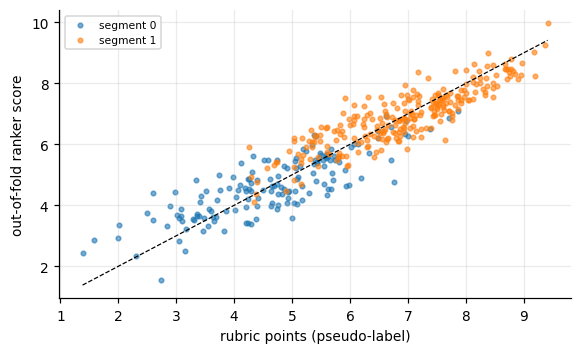

In [10]:
E["global_rank"] = E.points.rank(ascending=False, method="first")
print("Spearman, OOF score vs rubric points (all eligible):", round(spearmanr(E.points, E.score_oof)[0], 3))
fig, ax = plt.subplots(figsize=(6, 3.4))
for s, g in E.groupby("segment"):
    ax.scatter(g.points, g.score_oof, s=9, alpha=.6, label=f"segment {s}")
ax.plot([E.points.min(), E.points.max()], [E.points.min(), E.points.max()], "k--", lw=.8)
ax.set_xlabel("rubric points (pseudo-label)"); ax.set_ylabel("out-of-fold ranker score"); ax.legend(fontsize=7); plt.show()

---
## Step 4 — Documentation, and from model output to a funding list

*Budget: ~40.6h.*

### 4.1 Budget envelopes (our decision)

* 10% of the budget (CHF 50,000) is split **equally** across the segments (a floor);
* 90% is split **in proportion to each segment's total requested amount weighted by its mean rubric points**.
  Segments with more need and higher priority get more money;
* within each segment, applicants are funded in order of the out-of-fold ranker score, receiving 65% of their request
  (minimum CHF 1,000), until the envelope is used;
* any amount left in an envelope (because the next award does not fit) goes, at the end, to the best-scoring unfunded
  applicants overall.

For comparison we also run a **single global ranking** (rubric points, same award rule, no envelopes).

In [11]:
df["segment"] = E.segment.reindex(df.index); df["points"] = E.points.reindex(df.index)
df["score_oof"] = E.score_oof.reindex(df.index)
BUDGET, FRACTION, MIN_AWARD = 500_000, 0.65, 1000
pool = df[df.eligible & (df.request > 0)]

def allocate_envelopes(weight, floor):
    """envelopes = floor split equally + rest in proportion to weight; fund by ranker score within segment"""
    envelope = floor * BUDGET / len(weight) + (1 - floor) * BUDGET * weight / weight.sum()
    award = pd.Series(0.0, index=df.index)
    for s, g in pool.groupby("segment"):
        left = envelope[s]
        for sid in g.sort_values("score_oof", ascending=False).index:
            amt = float(np.floor(df.at[sid, "request"] * FRACTION))
            if amt < MIN_AWARD or amt > left:
                continue
            award[sid] = amt; left -= amt
    rest = BUDGET - award.sum()
    for sid in pool.sort_values("score_oof", ascending=False).index:     # leftovers: best unfunded overall
        amt = float(np.floor(df.at[sid, "request"] * FRACTION))
        if award[sid] == 0 and MIN_AWARD <= amt and rest >= MIN_AWARD:
            give = min(amt, rest); award[sid] = give; rest -= give
    return envelope, award

w1 = pool.groupby("segment").apply(lambda g: g.request.sum() * g.points.mean())
envelope, df["award"] = allocate_envelopes(w1, floor=0.10)
df["award_draft1"] = df.award
df["funding_rank"] = pool.score_oof.rank(ascending=False, method="first").reindex(df.index)   # global order of the score
display(pd.DataFrame({"applicants": pool.segment.value_counts().sort_index(), "requested": pool.groupby("segment").request.sum(),
                      "mean points": pool.groupby("segment").points.mean().round(2), "envelope (draft 1)": envelope.round(0)}))
print(f"DRAFT 1 funded: {(df.award > 0).sum()} | awarded CHF {df.award.sum():,.0f} | mean CHF {df.loc[df.award > 0, 'award'].mean():,.0f}")
print("funded by segment:", df.loc[df.award > 0, "segment"].value_counts().sort_index().to_dict())

,applicants,requested,mean points,envelope (draft 1)
segment,,,,
0.0,124,619140.0,4.76,131776.0
1.0,245,1371129.0,6.91,368224.0


DRAFT 1 funded: 141 | awarded CHF 500,000 | mean CHF 3,546
funded by segment: {0.0: 38, 1.0: 103}


In [12]:
# Comparison: one global ranking by rubric points, same award rule, no envelopes
g_award, left = pd.Series(0.0, index=df.index), BUDGET
for sid in pool.sort_values("points", ascending=False).index:
    amt = float(np.floor(df.at[sid, "request"] * FRACTION))
    if amt < MIN_AWARD: continue
    give = min(amt, left)
    if give < MIN_AWARD: break
    g_award[sid] = give; left -= give
df["award_global"] = g_award
only_env = df[(df.award > 0) & (df.award_global == 0)]; only_glob = df[(df.award == 0) & (df.award_global > 0)]
print(f"global ranking: {(g_award > 0).sum()} funded | funded only with draft-1 envelopes: {len(only_env)} | only with global ranking: {len(only_glob)}")
print("by segment, envelopes vs global:"); display(pd.DataFrame({"envelopes": df[df.award > 0].segment.value_counts(),
                                                                 "global": df[df.award_global > 0].segment.value_counts()}).fillna(0).astype(int).sort_index())
cols = ["segment", "points", "score_oof", "shortfall_ratio", "family_household_income_chf", "savings_chf", "gpa", "resil_count", "gni_tier", "request"]
print("funded only with envelopes (lowest points first):"); display(only_env.sort_values("points")[cols].head(4).round(3))
print("funded only with the global ranking (highest points first):"); display(only_glob.sort_values("points", ascending=False)[cols].head(4).round(3))

global ranking: 135 funded | funded only with draft-1 envelopes: 41 | only with global ranking: 35
by segment, envelopes vs global:


,envelopes,global
segment,,
0.0,38,4
1.0,103,131


funded only with envelopes (lowest points first):


,segment,points,score_oof,shortfall_ratio,family_household_income_chf,savings_chf,gpa,resil_count,gni_tier,request
STU000038,0.0,4.116,5.389,0.112,4940,0,3.60,3,2,2364.0
STU000273,0.0,4.324,5.625,0.420,1530,4993,2.40,5,1,7375.0
STU000055,0.0,4.514,5.477,0.255,4400,0,3.64,3,2,5136.0
STU000190,0.0,4.590,5.471,0.661,2540,9659,2.00,5,2,7333.0


funded only with the global ranking (highest points first):


,segment,points,score_oof,shortfall_ratio,family_household_income_chf,savings_chf,gpa,resil_count,gni_tier,request
STU000235,1.0,7.762,6.810,0.843,1110,8536,3.11,3,3,7333.0
STU000089,1.0,7.759,7.022,0.859,1240,0,2.86,2,1,2708.0
STU000261,1.0,7.754,6.933,0.867,870,0,3.10,2,1,7333.0
STU000420,1.0,7.642,6.152,0.459,1070,0,2.88,4,1,5958.0


In [13]:
def excerpt(sid, n=650):
    t = docs[sid]; i = t.find("## Section 4")
    return re.sub(r"\s+", " ", t[i:].split("\n", 3)[-1])[:n]
for sid in list(only_env.sort_values("points").index[:2]) + list(only_glob.sort_values("points", ascending=False).index[:2]):
    tag = "ENVELOPES ONLY" if sid in only_env.index else "GLOBAL ONLY"
    print(f"[{tag}] {sid} (segment {df.at[sid, 'segment']:.0f}, points {df.at[sid, 'points']:.2f}):", excerpt(sid), "...\n")

[ENVELOPES ONLY] STU000038 (segment 0, points 4.12):  My financial need is small, and I want to say this first. I study the Master in History part-time. My expenses are CHF 1,757 per month. I earn CHF 1,947 as a research assistant for a professor at the History department and as a teacher at a Saturday Vietnamese school, about 17 hours a week together. My spouse, who owns a small Vietnamese restaurant in Zurich with a household income of about CHF 4,940, gives CHF 370 for my part of our costs. I have no savings. So why do I apply? The restaurant is our only family income besides my work, and since the construction work on our street started this spring, we have lost about a third of our custome ...

[ENVELOPES ONLY] STU000273 (segment 0, points 4.32):  I study Educational Sciences at University of Bern, since February 2026. My costs are CHF 2,058 per month. My room is CHF 937, health insurance CHF 415. I work as an assistant in an after-school programme, 7 hours per week, and earn CHF 

**Human review (all four of us; two files each).** With the draft-1 envelopes (10% floor, 90% by requested amount × mean points), segment 0 receives CHF 131,776, **26% of the budget**, and funds 38 applicants. A single global ranking by the same rubric funds only 4 of them. 41 applicants are funded only because of the envelopes, and 35 only under the global ranking.

* **STU000038** (segment 0, shortfall ratio 0.11) opens: *"My financial need is small, and I want to say this first."* This part-time student earns more than their costs. They are funded in draft 1.
* **STU000273** (segment 0, shortfall ratio 0.42) describes a hearing impairment with real extra costs and a monthly gap of CHF 864. The two of us who read it consider this a fair award.
* **STU000235** and **STU000089** (segment 1, shortfall ratios 0.84 and 0.86; household CHF 1,110–1,240) are **not** funded in draft 1. Their segment's envelope is used up by applicants with similar profiles and higher ranker scores.

The envelopes reallocate money from high-need to low-need applicants. This was not our intention: we wanted to compare like with like, not to guarantee a share of the budget to applicants with smaller needs. The segmentation found need, and an envelope over a need segment works like a quota for lower need.

### 4.2 Revision of the envelopes

* **No floor**: a guaranteed share for a segment of low-need applicants is not something the call supports;
* envelope ∝ **the total request of the segment's applicants with a shortfall ratio of at least 0.5**, i.e. the money
  needed by applicants with substantial documented need in that segment;
* within segments, unchanged: out-of-fold ranker score, 65% of request, leftovers to the best unfunded overall.

In [14]:
w2 = pool.groupby("segment").apply(lambda g: g.request[g.shortfall_ratio >= 0.5].sum())
envelope2, df["award"] = allocate_envelopes(w2, floor=0.0)
display(pd.DataFrame({"envelope draft 1": envelope.round(0), "envelope final": envelope2.round(0)}))
f = df.award > 0
print(f"FINAL funded: {f.sum()} | awarded CHF {df.award.sum():,.0f} | mean CHF {df.loc[f, 'award'].mean():,.0f}")
print("funded by segment:", df.loc[f, "segment"].value_counts().sort_index().to_dict())
for name, col in [("draft 1", "award_draft1"), ("final", "award"), ("global", "award_global")]:
    sel = df[col] > 0
    print(f"{name:8s}: funded {sel.sum()}, median shortfall ratio {df.loc[sel, 'shortfall_ratio'].median():.2f}, "
          f"funded with shortfall ratio < 0.30: {(sel & (df.shortfall_ratio < 0.3)).sum()}")
print("final vs global ranking: same applicants funded:", (f & (df.award_global > 0)).sum())

,envelope draft 1,envelope final
segment,,
0.0,131776.0,77752.0
1.0,368224.0,422248.0


FINAL funded: 140 | awarded CHF 499,037 | mean CHF 3,565
funded by segment: {0.0: 23, 1.0: 117}
draft 1 : funded 141, median shortfall ratio 0.76, funded with shortfall ratio < 0.30: 9
final   : funded 140, median shortfall ratio 0.77, funded with shortfall ratio < 0.30: 4
global  : funded 135, median shortfall ratio 0.81, funded with shortfall ratio < 0.30: 1
final vs global ranking: same applicants funded: 109


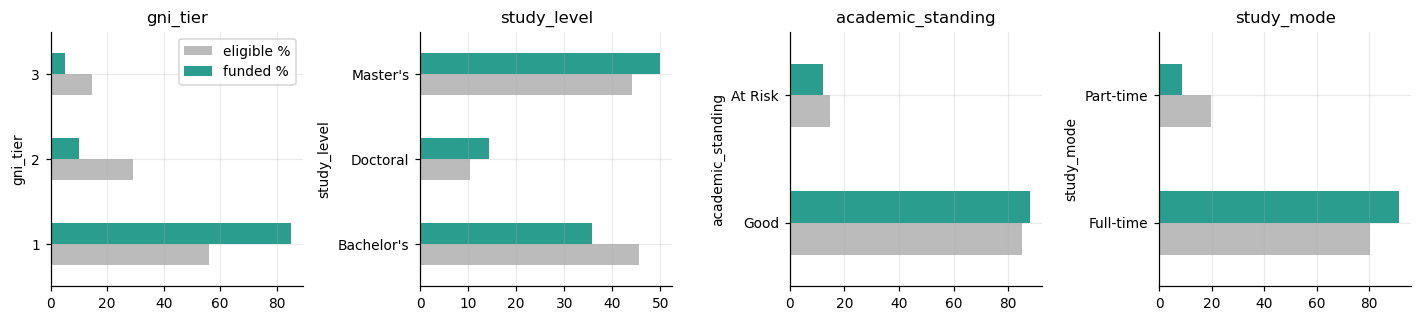

median shortfall ratio  funded: 0.77 | eligible not funded: 0.52


In [15]:
# Who is funded? Composition of the final list against the eligible pool
def share(col):
    e = df.loc[df.eligible, col].astype(str).value_counts(normalize=True).mul(100)
    f = df.loc[df.award > 0, col].astype(str).value_counts(normalize=True).mul(100)
    return pd.DataFrame({"eligible %": e, "funded %": f}).fillna(0).round(1)
fig, axs = plt.subplots(1, 4, figsize=(13, 3))
for ax, col in zip(axs, ["gni_tier", "study_level", "academic_standing", "study_mode"]):
    share(col).plot.barh(ax=ax, color=["#bbbbbb", "#2a9d8f"], legend=(col == "gni_tier"))
    ax.set_title(col)
plt.tight_layout(); plt.show()
print("median shortfall ratio  funded: %.2f | eligible not funded: %.2f" % (
    df.loc[df.award > 0, "shortfall_ratio"].median(), df.loc[df.eligible & (df.award == 0), "shortfall_ratio"].median()))

**Final list: 140 awards, CHF 499,037** (CHF 963 is left over because no further award fits). Segment 0's envelope drops from CHF 131,776 to CHF 77,752, and the number of its recipients from 38 to 23. Applicants funded with a shortfall ratio below 0.30: 9 in draft 1, **4 in the final list**, 1 under the global ranking. The final list shares 109 of its 140 recipients with the global ranking. The remaining differences come from the ranker (out-of-fold scores, not the rubric itself) and from the segment envelopes.

STU000089 is now funded; STU000038 is not. **STU000235** (shortfall ratio 0.84) is still not funded. Their ranker score (6.81) is well below their rubric points (7.76): the model weighs the CHF 8,536 in savings more heavily than our rubric does. We flag the case for the committee.

❓ **Question for students:** STU000235 is unfunded because the *model* disagrees with the *rubric* it was trained on. If a group writes the rubric itself, should the rubric or the model have the last word when they disagree? And what is the supervised stage for, if the answer is always the rubric?

Composition: 119 / 14 / 7 recipients from GNI tiers 1 / 2 / 3; 50 Bachelor's, 70 Master's, 20 Doctoral. 26 awards are conditional (17 for GPA below 2.5, the rest for pending permits). The median shortfall ratio is 0.77 among recipients against 0.52 among eligible applicants not funded.

In [16]:
# Output files: the full decision path (all 500) and the final allocation (funded only)
df["status"] = np.select([df.award > 0, ~df.eligible], [np.where(df.conditional, "funded (conditional)", "funded"),
                         "not eligible"], "eligible, not funded")
df["reason"] = np.select([df.award > 0, ~df.eligible], ["segment " + df.segment.astype("Int64").astype(str) + " envelope, ranker score " + df.score_oof.round(2).astype(str) + "; 65% of request", "failed: " + df[HARD].apply(lambda r: ", ".join(h for h in HARD if r[h].startswith("fail")), axis=1)], "eligible; segment envelope used before this applicant")
INPUTS = ["student_id", "study_level", "study_mode", "residency_permit", "gni_tier", "geographic_region", "gpa",
          "academic_standing", "need_2027", "shortfall_ratio", "family_household_income_chf", "savings_chf",
          "external_scholarship_amount_chf", "risk_count", "resil_count", "completion_year", "completion_month",
          "months_in_grant"]
STEPS = HARD + ["eligible", "conditional"] + ["segment", "points", "score_oof", "award_draft1", "award_global"] + ["request", "funding_rank", "award", "status", "reason"]
decision_progression = df[INPUTS + STEPS]
decision_progression.to_csv("decision_progression.csv", index=False)
final = decision_progression[decision_progression.award > 0].sort_values("funding_rank")
final.to_csv("final_allocation.csv", index=False)
print("decision_progression.csv:", decision_progression.shape, "| final_allocation.csv:", final.shape,
      f"| total CHF {final.award.sum():,.0f}")
final.head(8)

decision_progression.csv: (500, 37) | final_allocation.csv: (140, 37) | total CHF 499,037


,student_id,study_level,study_mode,residency_permit,gni_tier,geographic_region,gpa,academic_standing,need_2027,shortfall_ratio,family_household_income_chf,savings_chf,external_scholarship_amount_chf,risk_count,resil_count,...,H5,H6,H7,eligible,conditional,segment,points,score_oof,award_draft1,award_global,request,funding_rank,award,status,reason
STU000381,STU000381,Master's,Full-time,B,1,Sub-Saharan Africa,4.00,Good,1924,0.805358,960,0,7463,1,5,...,pass,pass,pass (assumed),True,False,1.0,9.411313,9.969648,3872.0,3872.0,5958.0,1.0,3872.0,funded,"segment 1 envelope, ranker score 9.97; 65% of ..."
STU000249,STU000249,Master's,Full-time,B,1,Sub-Saharan Africa,3.59,Good,2295,0.891262,1130,4284,0,1,5,...,pass,pass,pass (assumed),True,False,1.0,9.371505,9.253881,3872.0,3872.0,5958.0,2.0,3872.0,funded,"segment 1 envelope, ranker score 9.25; 65% of ..."
STU000345,STU000345,Bachelor's,Full-time,B,1,South Asia,2.97,Good,1180,0.736120,360,855,7797,1,5,...,pass,pass,pass (assumed),True,False,1.0,9.175908,9.042292,3791.0,3791.0,5833.0,3.0,3791.0,funded,"segment 1 envelope, ranker score 9.04; 65% of ..."
STU000198,STU000198,Doctoral,Full-time,B,1,South Asia,3.67,Good,2116,0.967978,430,14388,0,1,3,...,pass,pass,pass (assumed),True,False,1.0,8.381012,8.995408,2978.0,2978.0,4583.0,4.0,2978.0,funded,"segment 1 envelope, ranker score 9.0; 65% of r..."
STU000274,STU000274,Bachelor's,Full-time,Pending,1,Sub-Saharan Africa,3.13,Good,1960,0.937799,540,2375,5151,4,3,...,pass,pass,pass (assumed),True,True,1.0,8.775837,8.814475,4766.0,4766.0,7333.0,5.0,4766.0,funded (conditional),"segment 1 envelope, ranker score 8.81; 65% of ..."
STU000096,STU000096,Master's,Full-time,B,1,Sub-Saharan Africa,3.45,Good,1665,0.893240,1060,6318,0,0,5,...,pass,pass,pass (assumed),True,False,1.0,8.977044,8.674641,1760.0,1760.0,2708.0,6.0,1760.0,funded,"segment 1 envelope, ranker score 8.67; 65% of ..."
STU000470,STU000470,Master's,Full-time,F,1,Middle East/North Africa,3.51,Good,1025,0.450154,510,0,0,3,5,...,pass,pass,pass (assumed),True,False,1.0,8.136401,8.633467,3872.0,3872.0,5958.0,7.0,3872.0,funded,"segment 1 envelope, ranker score 8.63; 65% of ..."
STU000335,STU000335,Doctoral,Full-time,Pending,1,South Asia,3.63,Good,2263,0.930127,840,7717,0,5,3,...,pass,pass,pass (assumed),True,True,1.0,8.675030,8.631459,2978.0,2978.0,4583.0,8.0,2978.0,funded (conditional),"segment 1 envelope, ranker score 8.63; 65% of ..."


### 4.3 Which decisions are the model's, and which are ours

| Decision | Made by | How |
|---|---|---|
| Segmentation features and exclusions | Humans (us) | Step 3.1 |
| The segments | Model | k-means, k by silhouette, stability across seeds |
| Rubric (pseudo-label) | Humans (us) | Step 3.2 |
| Within-segment ranking score | Model | ridge regression per segment, out-of-fold predictions |
| Envelope per segment (draft 1: 10% floor + 90% weighted by points; final: need ≥ 0.5 requests) | Humans (us) | Steps 4.1–4.2 |
| Award rule: 65% of request, minimum CHF 1,000; savings above CHF 2,000 deducted | Humans (us) | Steps 1.3 and 4.1 |
| Envelopes revised after comparing with a global ranking and reading files | Humans (us) | Step 4.2 |


### 4.4 Reproducibility

Fixed seed (`SEED = 2026`) for k-means and CV folds. Specification: segmentation features (3.1), k-means
(`n_init=20`, k by silhouette over 2–8), rubric (3.2), ranker features and `RidgeCV(alphas=logspace(-2, 3, 20))`
with standardisation, 5-fold out-of-fold scores, envelopes and award rule (4.1–4.2).

### 4.5 Summary of our decision path

1. 500 → **413 eligible** (76 no shortfall in the grant period; 20 Permit C with household ≥ CHF 6,500). 74 of the eligible are conditional (GPA < 2.5 or pending permit).
2. Stage 1: k-means on seven need/merit features → **two segments, which turn out to be low need vs high need** (stable, weak silhouette).
3. Stage 2: within-segment ridge rankers trained on our points rubric. Out-of-fold R² 0.68 / 0.76, stable over fold seeds.
4. Draft 1 envelopes (floor + points-weighted) gave 26% of the budget to the low-need segment. File reading confirmed low-need awards (e.g. STU000038).
5. **Final:** envelopes ∝ requests of applicants with shortfall ratio ≥ 0.5, no floor → **140 awards, CHF 499,037**. One high-need case (STU000235) flagged where the model and the rubric disagree.

Output files: `decision_progression.csv` (all 500, segment, points, ranker score, draft-1, final and global-ranking awards) and `final_allocation.csv`.